# LAB 6 / HOMEWORK — Mở rộng Video Retrieval

Notebook này **mở rộng trực tiếp Lab 5**: Flickr8k keyframes → EasyOCR/PaddleOCR → YOLOv8n → CLIP RN50 → Elasticsearch → BM25 / kNN / RRF / Weighted Hybrid → FastAPI.

Các bất biến của Lab 5 được giữ nguyên: 300 frame, `random.seed(5)`, `np.random.seed(5)`, cùng headline ground truth, YOLOv8n, CLIP RN50 và Elasticsearch. Lab 6 bổ sung so sánh OCR công bằng, object search linh hoạt, khảo sát `rrf_k`, và Weighted Hybrid.


In [1]:
%pip install -q easyocr ultralytics open_clip_torch datasets "elasticsearch>=8,<9" fastapi uvicorn pyarrow paddleocr paddlepaddle


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
import os, json, time, random, subprocess, sys, platform, tarfile, urllib.request, zipfile
from collections import Counter
from functools import lru_cache
from pathlib import Path
from importlib.metadata import version as package_version

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from IPython.display import Markdown, display
from tqdm.auto import tqdm
from datasets import load_dataset
import easyocr
from paddleocr import PaddleOCR
from ultralytics import YOLO
import open_clip
from elasticsearch import Elasticsearch
from elasticsearch.helpers import bulk

random.seed(5)
np.random.seed(5)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
print("PaddleOCR:", package_version("paddleocr"), "| PaddlePaddle:", package_version("paddlepaddle"))


C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.5.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Device: cuda
PaddleOCR: 3.7.0 | PaddlePaddle: 3.3.1


---
# Part 1: Offline Pipeline — Từ Keyframe đến Metadata

```
Keyframe ──┬──▶ EasyOCR ────▶ easyocr_text ──┐
           ├──▶ PaddleOCR ──▶ paddleocr_text ─┴──▶ final ocr_text (PaddleOCR)
           ├──▶ YOLOv8n ────▶ objects
           └──▶ CLIP RN50 ──▶ clip_vector
```

Hai OCR engine đọc **đúng cùng một collection `frames`**. Chỉ PaddleOCR được gán vào `ocr_text` cuối cùng trước khi tạo document và index Elasticsearch.


[1/10] Tải Flickr8k & tạo keyframe giả lập bản tin...
      => 300 keyframes, trong đó 118 frame có headline bản tin


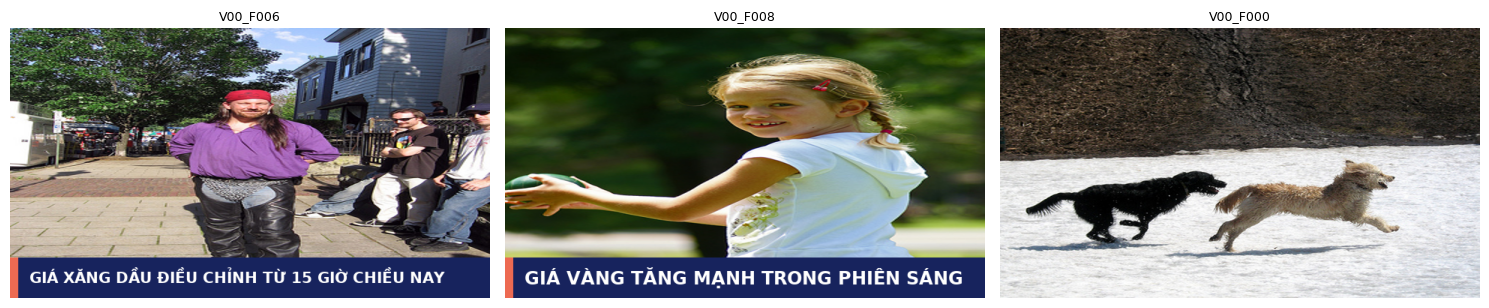

In [3]:
print("[1/10] Tải Flickr8k & tạo keyframe giả lập bản tin...")
NUM_FRAMES = 300      # chạy CPU? giảm còn 100
BANNER_RATIO = 0.4    # ~40% frame được in headline

raw = load_dataset("jxie/flickr8k", split="train")
sample = raw.select(range(NUM_FRAMES))

HEADLINES = [
    "GIÁ VÀNG TĂNG MẠNH TRONG PHIÊN SÁNG",
    "GIÁ VÀNG GIẢM NHẸ SAU BA PHIÊN TĂNG",
    "ĐÀM PHÁN MỸ - IRAN NỐI LẠI TẠI VIENNA",
    "CĂNG THẲNG MỸ - IRAN TIẾP TỤC LEO THANG",
    "XUẤT KHẨU GẠO VIỆT NAM ĐẠT KỶ LỤC MỚI",
    "TP.HCM KHỞI CÔNG TUYẾN METRO SỐ 2",
    "CẢNH BÁO ÙN TẮC KÉO DÀI TRÊN QUỐC LỘ 1",
    "GIÁ XĂNG DẦU ĐIỀU CHỈNH TỪ 15 GIỜ CHIỀU NAY",
    "THỜI TIẾT NAM BỘ MƯA RÀO VÀ DÔNG VỀ CHIỀU",
    "ĐỘI TUYỂN VIỆT NAM THẮNG TRẬN GIAO HỮU",
]

# Font có dấu tiếng Việt — DejaVu Sans đi kèm matplotlib, không cần tải thêm
FONT_BOLD = fm.findfont(fm.FontProperties(family="DejaVu Sans", weight="bold"))

def make_keyframe(img, headline=None):
    """Chuẩn hóa keyframe 640x360; nếu có headline thì vẽ lower-third kiểu bản tin."""
    img = img.convert("RGB").resize((640, 360))
    if headline is None:
        return img
    d = ImageDraw.Draw(img)
    W, H = img.size
    bar_h = 54
    d.rectangle([0, H - bar_h, W, H], fill=(23, 35, 93))    # thanh navy
    d.rectangle([0, H - bar_h, 10, H], fill=(237, 106, 82)) # tab coral
    size = 26
    font = ImageFont.truetype(FONT_BOLD, size)
    while d.textlength(headline, font=font) > W - 44 and size > 12:
        size -= 2
        font = ImageFont.truetype(FONT_BOLD, size)
    d.text((26, H - bar_h // 2), headline, font=font, fill="white", anchor="lm")
    return img

os.makedirs("keyframes", exist_ok=True)
frames = []
for i in range(NUM_FRAMES):
    head = random.choice(HEADLINES) if random.random() < BANNER_RATIO else None
    img = make_keyframe(sample[i]["image"], head)
    fid = f"V{i // 30:02d}_F{i % 30:03d}"            # 10 "video", mỗi video 30 keyframe
    img.save(f"keyframes/{fid}.jpg", quality=90)
    frames.append({"frame_id": fid, "video_id": f"video_{i // 30:02d}",
                   "ts": round((i % 30) * 2.0, 1),   # keyframe cách nhau 2 giây
                   "image": img, "caption": sample[i]["caption_0"], "gt_headline": head})

n_banner = sum(f["gt_headline"] is not None for f in frames)
print(f"      => {len(frames)} keyframes, trong đó {n_banner} frame có headline bản tin")

show = [f for f in frames if f["gt_headline"]][:2] + [f for f in frames if not f["gt_headline"]][:1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, f in zip(axes, show):
    ax.imshow(f["image"]); ax.set_title(f["frame_id"], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Task 2 — EasyOCR vs PaddleOCR

Thời gian khởi tạo và tải model được đặt ngoài phép đo. Cả hai engine dùng confidence threshold `0.3`, cùng ảnh, cùng headline và cùng định nghĩa `word_recall`; một frame được tính hit khi recall từ đạt ít nhất 60%.


In [4]:
print("[2/10] EasyOCR (pretrained, vi + en)...")
OCR_CONFIDENCE = 0.3
OCR_HIT_THRESHOLD = 0.60

# Khởi tạo/download model không nằm trong thời gian inference.
easy_reader = easyocr.Reader(["vi", "en"], gpu=(device == "cuda"))
easy_start = time.perf_counter()
for f in tqdm(frames, desc="EasyOCR"):
    detections = easy_reader.readtext(np.array(f["image"]))
    f["easyocr_dets"] = detections
    f["easyocr_text"] = " ".join(
        text for _, text, confidence in detections if confidence >= OCR_CONFIDENCE
    )
easyocr_seconds = time.perf_counter() - easy_start
print(f"      => EasyOCR {len(frames)} frames trong {easyocr_seconds:.2f}s")

def word_recall(gt, pred):
    """Tỉ lệ từ của ground-truth headline xuất hiện trong text OCR đọc được."""
    words = gt.lower().split()
    return sum(word in pred.lower() for word in words) / len(words)

stamped = [f for f in frames if f["gt_headline"]]


[2/10] EasyOCR (pretrained, vi + en)...


EasyOCR:   0%|          | 0/300 [00:00<?, ?it/s]

      => EasyOCR 300 frames trong 17.21s


In [5]:
print("[3/10] PaddleOCR tiếng Việt...")

def make_paddle_reader():
    """Khởi tạo đúng API đang cài; thử tham số 3.x rồi tương thích 2.x."""
    try:
        return PaddleOCR(
            lang="vi",
            use_doc_orientation_classify=False,
            use_doc_unwarping=False,
            use_textline_orientation=False,
            enable_mkldnn=False,
        )
    except (TypeError, ValueError):
        return PaddleOCR(lang="vi", use_angle_cls=False, show_log=False, enable_mkldnn=False)


def extract_paddle_lines(result, confidence_threshold=OCR_CONFIDENCE):
    """Trích `(text, confidence)` an toàn từ PaddleOCR 2.x hoặc 3.x."""
    extracted = []

    def add(text, confidence):
        if text is None:
            return
        text = str(text).strip()
        if not text:
            return
        try:
            score = None if confidence is None else float(confidence)
        except (TypeError, ValueError):
            score = None
        if score is None or score >= confidence_threshold:
            extracted.append((text, score))

    def walk(node):
        if node is None:
            return
        if hasattr(node, "to_dict") and not isinstance(node, dict):
            try:
                walk(node.to_dict())
                return
            except Exception:
                pass
        if isinstance(node, dict):
            texts = node.get("rec_texts")
            scores = node.get("rec_scores")
            if texts is not None:
                score_values = list(scores) if scores is not None else [None] * len(texts)
                for text, score in zip(list(texts), score_values):
                    add(text, score)
                return
            if "text" in node:
                add(node.get("text"), node.get("score", node.get("confidence")))
                return
            for key in ("res", "result", "data", "ocr_res"):
                if key in node:
                    walk(node[key])
            return
        if isinstance(node, (list, tuple)):
            # Legacy line: [bbox, (text, confidence)]
            if len(node) >= 2 and isinstance(node[1], (list, tuple)):
                recognition = node[1]
                if len(recognition) >= 2 and isinstance(recognition[0], str):
                    add(recognition[0], recognition[1])
                    return
            # Some versions expose direct [text, confidence].
            if len(node) >= 2 and isinstance(node[0], str):
                add(node[0], node[1])
                return
            for child in node:
                walk(child)

    walk(result)
    # Version-specific wrappers can expose the same recognition twice.
    unique = []
    seen = set()
    for text, score in extracted:
        key = (text, None if score is None else round(score, 8))
        if key not in seen:
            seen.add(key)
            unique.append((text, score))
    return unique


def paddle_predict(reader, image):
    array = np.array(image)
    if hasattr(reader, "predict"):
        return list(reader.predict(array))
    return reader.ocr(array, cls=False)


# Khởi tạo/download model không nằm trong thời gian inference.
paddle_reader = make_paddle_reader()
paddle_start = time.perf_counter()
for f in tqdm(frames, desc="PaddleOCR"):
    raw_result = paddle_predict(paddle_reader, f["image"])
    lines = extract_paddle_lines(raw_result)
    f["paddleocr_lines"] = lines
    f["paddleocr_text"] = " ".join(text for text, _ in lines)
paddleocr_seconds = time.perf_counter() - paddle_start
print(f"      => PaddleOCR {len(frames)} frames trong {paddleocr_seconds:.2f}s")


[3/10] PaddleOCR tiếng Việt...


C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Admin\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Admin\.paddlex\official_models\PP-OCRv6_medium_rec`.


PaddleOCR:   0%|          | 0/300 [00:00<?, ?it/s]

      => PaddleOCR 300 frames trong 858.25s


In [6]:
easy_hits = sum(
    word_recall(f["gt_headline"], f["easyocr_text"]) >= OCR_HIT_THRESHOLD for f in stamped
)
paddle_hits = sum(
    word_recall(f["gt_headline"], f["paddleocr_text"]) >= OCR_HIT_THRESHOLD for f in stamped
)
ocr_comparison_df = pd.DataFrame([
    {
        "Engine": "EasyOCR",
        "Hits": easy_hits,
        "Banner frames": len(stamped),
        "Hit-rate (%)": 100 * easy_hits / len(stamped),
        "Total OCR time (s)": easyocr_seconds,
        "Time/frame (s)": easyocr_seconds / len(frames),
    },
    {
        "Engine": "PaddleOCR",
        "Hits": paddle_hits,
        "Banner frames": len(stamped),
        "Hit-rate (%)": 100 * paddle_hits / len(stamped),
        "Total OCR time (s)": paddleocr_seconds,
        "Time/frame (s)": paddleocr_seconds / len(frames),
    },
])
display(ocr_comparison_df.round(4))

# Từ đây trở đi, toàn bộ document và benchmark dùng OCR cuối cùng của PaddleOCR.
for f in frames:
    f["ocr_text"] = f["paddleocr_text"]
print("      => Đã gán PaddleOCR vào ocr_text cuối cùng cho", len(frames), "frames")


,Engine,Hits,Banner frames,Hit-rate (%),Total OCR time (s),Time/frame (s)
0,EasyOCR,118,118,100.0000,17.2081,0.0574
1,PaddleOCR,30,118,25.4237,858.2468,2.8608


      => Đã gán PaddleOCR vào ocr_text cuối cùng cho 300 frames


### Nhận xét đo được — OCR

EasyOCR có hit-rate cao hơn trong thí nghiệm (100.0% so với 25.4%). EasyOCR chạy nhanh hơn theo thời gian đo inference: EasyOCR 0.0574 s/frame, PaddleOCR 2.8608 s/frame. Kết quả cho thấy đánh đổi accuracy/tốc độ phải được kết luận từ số đo trên cùng tập frame, không từ giả định về engine.


[4/10] Object Detection với YOLOv8n (pretrained COCO, 80 lớp)...


Detect:   0%|          | 0/300 [00:00<?, ?it/s]

      => Detect 300 frames trong 4.5s
      => Top 10 lớp phổ biến: [('person', 497), ('dog', 62), ('car', 37), ('bird', 23), ('frisbee', 9), ('bicycle', 8), ('potted plant', 8), ('skateboard', 8), ('sports ball', 8), ('chair', 8)]
      => Frame thỏa (≥2 người & ≥1 ô tô): 10
      => Frame thỏa (≥2 người & ≥3 ô tô): 3


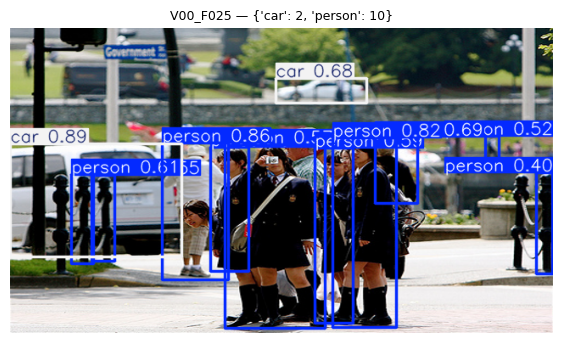

In [7]:
print("[4/10] Object Detection với YOLOv8n (pretrained COCO, 80 lớp)...")
yolo = YOLO("yolov8n.pt")

t0 = time.time()
for f in tqdm(frames, desc="Detect"):
    r = yolo.predict(f["image"], conf=0.4, verbose=False)[0]
    f["objects"] = dict(Counter(r.names[int(c)] for c in r.boxes.cls))
print(f"      => Detect {len(frames)} frames trong {time.time() - t0:.1f}s")

all_objs = Counter()
for f in frames:
    all_objs.update(f["objects"])
print("      => Top 10 lớp phổ biến:", all_objs.most_common(10))

# Đếm thử cho Query C (bài giảng: ≥2 người & ≥3 ô tô — Flickr8k ít cảnh phố nên demo ≥1 ô tô)
def count_ok(f, person=2, car=1):
    return f["objects"].get("person", 0) >= person and f["objects"].get("car", 0) >= car
print("      => Frame thỏa (≥2 người & ≥1 ô tô):", sum(count_ok(f) for f in frames))
print("      => Frame thỏa (≥2 người & ≥3 ô tô):", sum(count_ok(f, 2, 3) for f in frames))

f1 = max(frames, key=lambda f: f["objects"].get("person", 0) + f["objects"].get("car", 0))
plt.figure(figsize=(7, 4))
plt.imshow(yolo.predict(f1["image"], conf=0.4, verbose=False)[0].plot()[:, :, ::-1])
plt.axis("off"); plt.title(f"{f1['frame_id']} — {f1['objects']}", fontsize=9)
plt.show()

In [8]:
print("[5/10] CLIP RN50 embeddings (như Lab 4)...")
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    "RN50", pretrained="openai", device=device)
clip_tok = open_clip.get_tokenizer("RN50")
clip_model.eval()

BATCH = 64
vecs = []
with torch.no_grad():
    for i in tqdm(range(0, len(frames), BATCH), desc="CLIP"):
        batch = torch.stack([preprocess(f["image"]) for f in frames[i:i + BATCH]]).to(device)
        vecs.append(F.normalize(clip_model.encode_image(batch), dim=-1).cpu().numpy())
clip_vecs = np.vstack(vecs).astype("float32")
print("      => Ma trận embedding:", clip_vecs.shape)

[5/10] CLIP RN50 embeddings (như Lab 4)...


C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP:   0%|          | 0/5 [00:00<?, ?it/s]

      => Ma trận embedding: (300, 1024)


In [9]:
print("[6/10] Đóng gói documents...")
docs = []
for f, v in zip(frames, clip_vecs):
    docs.append({
        "frame_id": f["frame_id"], "video_id": f["video_id"], "ts": f["ts"],
        "caption": f["caption"], "ocr_text": f["ocr_text"],
        "objects": f["objects"], "clip_vector": v.tolist(),
    })

pd.DataFrame(docs).drop(columns=["clip_vector"]).to_parquet("keyframe_metadata.parquet")
with open("keyframe_docs.json", "w", encoding="utf-8") as fh:
    json.dump(docs, fh, ensure_ascii=False)

d0 = next(d for d in docs if d["ocr_text"])
print(f"      => {len(docs)} documents. Ví dụ:")
print(json.dumps({k: (v if k != "clip_vector" else f"[{len(v)} floats]") for k, v in d0.items()},
                 ensure_ascii=False, indent=2))

[6/10] Đóng gói documents...
      => 300 documents. Ví dụ:
{
  "frame_id": "V00_F006",
  "video_id": "video_00",
  "ts": 12.0,
  "caption": "A man dressed in a purple shirt and red bandanna smiles at the people watching him .",
  "ocr_text": "GIÁ XĂNG DÂU ĐIÊU CHNH TÙ 15 GIÒ CHIÊU NAY",
  "objects": {
    "person": 3,
    "truck": 1
  },
  "clip_vector": "[1024 floats]"
}


---
# Part 2: Elasticsearch — Inverted Index, kNN & Hybrid Search

**Elasticsearch** = search engine phân tán, chuẩn công nghiệp cho full-text search. Ba khả năng ta dùng:

| Kiểu field | Cấu trúc bên dưới | Truy vấn | Trả lời cho |
|---|---|---|---|
| `text` | **Inverted index** (từ → danh sách doc) | `match`, `match_phrase` — chấm điểm **BM25** | Query A, B (chữ OCR) |
| `integer` | BKD tree | `range` filter (không chấm điểm) | Query C (đếm object) |
| `dense_vector` | **HNSW** graph | `knn` — cosine similarity | Query ngữ nghĩa (CLIP) |

**Analyzer bỏ dấu (`asciifolding`):** OCR hay đọc sai dấu tiếng Việt ("GIÁ" → "GIA"). Ta khai báo analyzer `lowercase + asciifolding` cho field text: cả document lẫn query đều bị bỏ dấu khi phân tích → "gia vang" vẫn khớp "giá vàng".

**Hybrid Search bằng RRF:** BM25 giỏi khớp chuỗi ký tự đúng nghĩa đen; kNN CLIP giỏi hiểu mô tả ngữ cảnh nhưng "mù chữ". RRF trộn 2 bảng xếp hạng mà không cần chuẩn hóa điểm số — chỉ dùng **thứ hạng**.

> **Chạy local?** Không cần cell cài đặt bên dưới — chỉ cần Docker:
> ```
> docker run -d --name es -p 9200:9200 -e discovery.type=single-node \
>   -e xpack.security.enabled=false docker.elastic.co/elasticsearch/elasticsearch:8.11.4
> ```

In [10]:
print("[7/10] Khởi động Elasticsearch 8.x...")
ES_URL = "http://localhost:9200"
ES_VER = "8.11.4"

def es_up():
    try:
        return requests.get(ES_URL, timeout=2).status_code == 200
    except requests.exceptions.RequestException:
        return False

es_process = None
if not es_up():
    system = platform.system()
    archive_suffix = "windows-x86_64.zip" if system == "Windows" else "linux-x86_64.tar.gz"
    archive = Path(f"elasticsearch-{ES_VER}-{archive_suffix}")
    es_home = Path(f"elasticsearch-{ES_VER}")
    if not es_home.exists():
        url = f"https://artifacts.elastic.co/downloads/elasticsearch/elasticsearch-{ES_VER}-{archive_suffix}"
        print("      => Tải Elasticsearch:", url)
        if not archive.exists():
            urllib.request.urlretrieve(url, archive)
        if system == "Windows":
            with zipfile.ZipFile(archive) as bundle:
                bundle.extractall(".")
        else:
            with tarfile.open(archive) as bundle:
                bundle.extractall(".")

    env = os.environ.copy()
    env["ES_JAVA_OPTS"] = "-Xms1g -Xmx1g"
    es_log_handle = open("es_boot.log", "w", encoding="utf-8")
    if system == "Windows":
        command = [
            "cmd", "/c", str(es_home / "bin" / "elasticsearch.bat"),
            "-E", "xpack.security.enabled=false",
            "-E", "discovery.type=single-node",
        ]
        es_process = subprocess.Popen(
            command, stdout=es_log_handle, stderr=subprocess.STDOUT, env=env,
            creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0),
        )
    else:
        command = [
            str(es_home / "bin" / "elasticsearch"),
            "-E", "xpack.security.enabled=false",
            "-E", "discovery.type=single-node",
        ]
        es_process = subprocess.Popen(command, stdout=es_log_handle, stderr=subprocess.STDOUT, env=env)

    print("      => Chờ Elasticsearch sẵn sàng...")
    for _ in range(120):
        if es_up():
            break
        if es_process.poll() is not None:
            break
        time.sleep(2)

assert es_up(), "Elasticsearch chưa chạy — xem es_boot.log để biết lỗi thật"
print("      => Elasticsearch", requests.get(ES_URL).json()["version"]["number"], "READY")
es = Elasticsearch(ES_URL, request_timeout=120, max_retries=3, retry_on_timeout=True)


[7/10] Khởi động Elasticsearch 8.x...
      => Chờ Elasticsearch sẵn sàng...
      => Elasticsearch 8.11.4 READY


In [11]:
print("[8/10] Tạo index + bulk insert...")
INDEX = "keyframes"

SETTINGS = {  # analyzer bỏ dấu: "gia vang" vẫn khớp "giá vàng" (chống OCR mất dấu)
    "analysis": {"analyzer": {"vi_folded": {
        "tokenizer": "standard", "filter": ["lowercase", "asciifolding"]}}}}

MAPPINGS = {"properties": {
    "frame_id": {"type": "keyword"},
    "video_id": {"type": "keyword"},
    "ts":       {"type": "float"},
    "caption":  {"type": "text", "analyzer": "vi_folded"},
    "ocr_text": {"type": "text", "analyzer": "vi_folded"},
    # các lớp COCO khác (dog, bus, ...) ES tự map integer nhờ dynamic mapping
    "objects":  {"properties": {"person": {"type": "integer"}, "car": {"type": "integer"}}},
    "clip_vector": {"type": "dense_vector", "dims": int(clip_vecs.shape[1]),
                    "index": True, "similarity": "cosine"},
}}

es.indices.delete(index=INDEX, ignore_unavailable=True)
es.indices.create(index=INDEX, settings=SETTINGS, mappings=MAPPINGS)
bulk(es, ({"_index": INDEX, "_id": d["frame_id"], **d} for d in docs), chunk_size=50, request_timeout=120)
es.indices.refresh(index=INDEX)
print(f"      => Đã index {es.count(index=INDEX)['count']} documents")
print("      => Analyzer 'GIÁ VÀNG TĂNG' →",
      [t["token"] for t in es.indices.analyze(index=INDEX, analyzer="vi_folded",
                                              text="GIÁ VÀNG TĂNG")["tokens"]])

[8/10] Tạo index + bulk insert...


C:\Users\Admin\AppData\Local\Temp\ipykernel_35744\3932395160.py:22: DeprecationWarning: Passing transport options in the API method is deprecated. Use 'Elasticsearch.options()' instead.
  bulk(es, ({"_index": INDEX, "_id": d["frame_id"], **d} for d in docs), chunk_size=50, request_timeout=120)


      => Đã index 300 documents
      => Analyzer 'GIÁ VÀNG TĂNG' → ['gia', 'vang', 'tang']


## Task 1 — Flexible Object Search

Mỗi điều kiện được tách bằng dấu `:` cuối cùng nên các lớp COCO có khoảng trắng như `dining table` vẫn hợp lệ. Mỗi cặp sinh một `range` filter động và mọi filter được kết hợp bằng `bool.filter`.


In [12]:
print("[9/10] Practice text search và flexible object search\n")

def show_hits(res, cols=("frame_id", "ocr_text", "caption"), n=5):
    rows = []
    for hit in res["hits"]["hits"][:n]:
        source = hit["_source"]
        rows.append({
            "score": round(float(hit.get("_score") or 0.0), 3),
            **{name: str(source.get(name, ""))[:55] for name in cols},
            "objects": source.get("objects", {}),
            "image_path": f"/keyframes/{source['frame_id']}.jpg",
        })
    display(pd.DataFrame(rows))

def parse_object_conditions(want):
    valid_classes = set(yolo.names.values())
    parsed = []
    seen = set()
    for raw in want.split(","):
        if ":" not in raw:
            raise ValueError(f"Điều kiện '{raw}' phải có dạng COCO-class:count")
        name, count_text = (part.strip() for part in raw.rsplit(":", 1))
        if not name or name not in valid_classes:
            raise ValueError(f"Lớp COCO không hợp lệ: '{name}'")
        if not count_text.isdigit():
            raise ValueError(f"Số lượng của '{name}' phải là số nguyên không âm")
        if name in seen:
            raise ValueError(f"Lớp COCO bị lặp: '{name}'")
        seen.add(name)
        parsed.append((name, int(count_text)))
    return parsed

def object_search(want, top_k=5):
    conditions = parse_object_conditions(want)
    filters = [
        {"range": {f"objects.{name}": {"gte": minimum}}}
        for name, minimum in conditions
    ]
    return es.search(index=INDEX, size=top_k, query={"bool": {"filter": filters}})

resA = es.search(index=INDEX, size=5, query={"match": {"ocr_text": "giá vàng tăng"}})
print("A. BM25 'giá vàng tăng' —", resA["hits"]["total"]["value"], "hits")
show_hits(resA)

for want in ("person:2,car:1", "person:2,car:1,dog:1"):
    result = object_search(want=want, top_k=5)
    print(f"Object want={want!r} — {result['hits']['total']['value']} hits")
    show_hits(result, cols=("frame_id", "caption"))

try:
    parse_object_conditions("person:abc")
except ValueError as error:
    print("Malformed object query được từ chối:", error)


[9/10] Practice text search và flexible object search

A. BM25 'giá vàng tăng' — 31 hits


,score,frame_id,ocr_text,caption,objects,image_path
0,6.23,V00_F008,GIÁ VÀNG TĂNG MNH TRONG PHIÊN SÁNG,A girl in a white dress .,{'bird': 1},/keyframes/V00_F008.jpg
1,6.23,V00_F020,GIÁ VÀNG TĂNG MANH TRONG PHIÊN SÁNG,"a boy in a red shirt , in front of a long blue...",{'person': 1},/keyframes/V00_F020.jpg
2,6.23,V02_F012,GIÁ VÀNG TĂNG MNH TRONG PHIÊN SÁNG,A man in black shirt sits on a stool while try...,{'person': 3},/keyframes/V02_F012.jpg
3,6.23,V02_F020,GIÁ VÀNG TĂNG MNH TRONG PHIÊN SÁNG,A group of people surf on a very large wave .,{'person': 3},/keyframes/V02_F020.jpg
4,6.23,V02_F028,GIÁ VÀNG TĂNG MANH TRONG PHIÊN SÁNG,A girl wearing white polka dots and black boot...,{'person': 1},/keyframes/V02_F028.jpg


Object want='person:2,car:1' — 10 hits


,score,frame_id,caption,objects,image_path
0,0.0,V00_F025,A group of 5 girls in school uniforms are stan...,"{'car': 2, 'person': 10}",/keyframes/V00_F025.jpg
1,0.0,V01_F025,A man wearing a black hat is walking through a...,"{'person': 3, 'car': 1}",/keyframes/V01_F025.jpg
2,0.0,V02_F027,A driver is at the wheel of a race car .,"{'car': 1, 'person': 2}",/keyframes/V02_F027.jpg
3,0.0,V04_F025,Lacrosse players struggling for control of the...,"{'person': 4, 'car': 2, 'baseball bat': 1}",/keyframes/V04_F025.jpg
4,0.0,V05_F015,Children in red shirts play in the leaves .,"{'person': 2, 'car': 1}",/keyframes/V05_F015.jpg


Object want='person:2,car:1,dog:1' — 0 hits


""


Malformed object query được từ chối: Số lượng của 'person' phải là số nguyên không âm


K. kNN 'a dog running on the grass'


,score,frame_id,caption,objects,image_path
0,0.639,V07_F000,a dog runs across the grass .,{'dog': 1},/keyframes/V07_F000.jpg
1,0.638,V09_F017,A brown dog jumps high in the grass .,{'dog': 1},/keyframes/V09_F017.jpg
2,0.626,V02_F016,A brown dog playing with bubbles .,{'dog': 1},/keyframes/V02_F016.jpg
3,0.625,V06_F021,A brown and white dog runs across the grass .,{'dog': 1},/keyframes/V06_F021.jpg
4,0.624,V06_F011,A brown dog is running on grass .,{'dog': 1},/keyframes/V06_F011.jpg


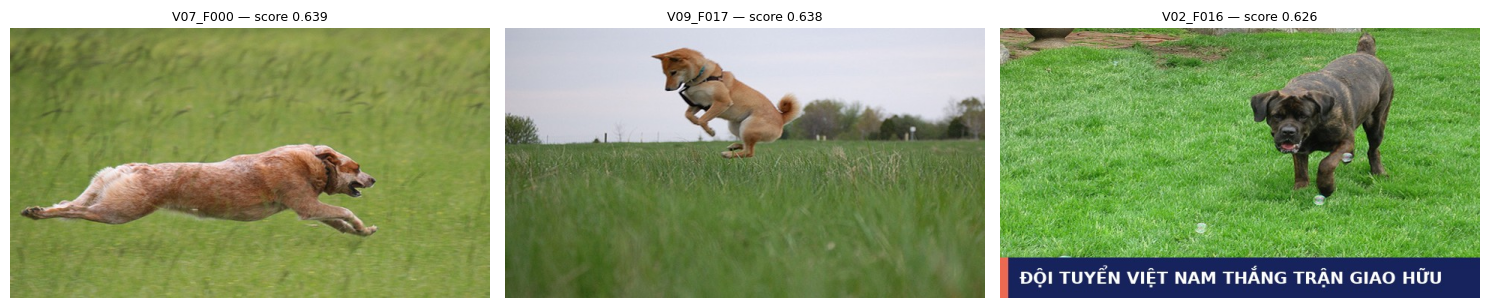

In [13]:
# ---- kNN semantic: mô tả ngữ cảnh tự do — KHÔNG cần chữ nào xuất hiện trong hình
def clip_text_vec(q):
    with torch.no_grad():
        v = F.normalize(clip_model.encode_text(clip_tok([q]).to(device)), dim=-1)
    return v.cpu().numpy()[0].tolist()

Q_SEM = "a dog running on the grass"
resK = es.search(index=INDEX, size=5, knn={"field": "clip_vector",
    "query_vector": clip_text_vec(Q_SEM), "k": 5, "num_candidates": 100})
print(f"K. kNN '{Q_SEM}'")
show_hits(resK, cols=("frame_id", "caption"))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, h in zip(axes, resK["hits"]["hits"][:3]):
    fid = h["_source"]["frame_id"]
    ax.imshow(Image.open(f"keyframes/{fid}.jpg"))
    ax.set_title(f"{fid} — score {h['_score']:.3f}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
print("[10/10] Benchmark: BM25 vs kNN (CLIP) vs Hybrid (RRF)...")

# Giữ nguyên collection query/ground truth của Lab 5 [9/9].
queries = []
by_head = {}
for f in frames:
    if f["gt_headline"]:
        by_head.setdefault(f["gt_headline"], set()).add(f["frame_id"])
for headline, ground_truth in by_head.items():
    queries.append((headline.lower(), ground_truth, "OCR-text"))
for f in [f for f in frames if not f["gt_headline"]][:100]:
    queries.append((f["caption"], {f["frame_id"]}, "Semantic"))

@lru_cache(maxsize=None)
def retrieve_branches(q):
    bm25_response = es.search(index=INDEX, size=30, query={"match": {"ocr_text": q}})
    knn_response = es.search(index=INDEX, size=30, knn={
        "field": "clip_vector", "query_vector": clip_text_vec(q),
        "k": 30, "num_candidates": 100,
    })
    bm25 = tuple(
        (hit["_source"]["frame_id"], float(hit["_score"]))
        for hit in bm25_response["hits"]["hits"]
    )
    knn = tuple(
        (hit["_source"]["frame_id"], float(hit["_score"]))
        for hit in knn_response["hits"]["hits"]
    )
    return bm25, knn

def bm25_ids(q, k=10):
    return [frame_id for frame_id, _ in retrieve_branches(q)[0][:k]]

def knn_ids(q, k=10):
    return [frame_id for frame_id, _ in retrieve_branches(q)[1][:k]]

def rrf_fuse(lists, k=60, top=10):
    scores = Counter()
    for ranked_ids in lists:
        for rank, frame_id in enumerate(ranked_ids, start=1):
            scores[frame_id] += 1.0 / (k + rank)
    return [
        frame_id for frame_id, _ in
        sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:top]
    ]

def hybrid_ids(q, k=10, rrf_k=60):
    return rrf_fuse([bm25_ids(q, 30), knn_ids(q, 30)], k=rrf_k, top=k)

def evaluate(search_fn):
    stats = {}
    start = time.perf_counter()
    for q, ground_truth, group in queries:
        ids = search_fn(q, 10)
        rank = next((i + 1 for i, frame_id in enumerate(ids) if frame_id in ground_truth), None)
        values = stats.setdefault(group, [0, 0, 0, 0.0])
        values[0] += 1
        if rank is not None:
            values[1] += rank == 1
            values[2] += rank <= 5
            values[3] += 1.0 / rank
    return stats, (time.perf_counter() - start) * 1000 / len(queries)

def group_metrics(stats, group):
    n, hit1, hit5, mrr_sum = stats[group]
    return {"R@1": 100 * hit1 / n, "R@5": 100 * hit5 / n, "MRR": mrr_sum / n}

systems = [
    ("BM25 (ocr_text)", bm25_ids),
    ("kNN (CLIP)", knn_ids),
    ("Hybrid (RRF k=60)", lambda q, k: hybrid_ids(q, k, rrf_k=60)),
]
baseline_rows = []
baseline_results = {}
for name, search_fn in systems:
    stats, latency = evaluate(search_fn)
    baseline_results[name] = (stats, latency)
    for group in ("OCR-text", "Semantic"):
        baseline_rows.append({"System": name, "Group": group, **group_metrics(stats, group),
                              "Latency/query (ms)": latency})
baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df.round(4))


[10/10] Benchmark: BM25 vs kNN (CLIP) vs Hybrid (RRF)...


,System,Group,R@1,R@5,MRR,Latency/query (ms)
0,BM25 (ocr_text),OCR-text,100.0,100.0,1.0000,72.5695
1,BM25 (ocr_text),Semantic,1.0,6.0,0.0248,72.5695
2,kNN (CLIP),OCR-text,80.0,90.0,0.8500,0.0042
3,kNN (CLIP),Semantic,75.0,95.0,0.8333,0.0042
4,Hybrid (RRF k=60),OCR-text,100.0,100.0,1.0000,0.0316
5,Hybrid (RRF k=60),Semantic,46.0,89.0,0.6378,0.0316


Kết quả nền dùng cùng index PaddleOCR và cho thấy từng nhánh giữ thế mạnh riêng: BM25 dựa vào chữ OCR, còn CLIP kNN dựa vào nội dung hình ảnh. RRF kết hợp hai bảng xếp hạng theo cách đối xứng; các khảo sát tiếp theo chỉ thay tham số fusion, không thay query hay ground truth.


## Task 3 — RRF Parameter Study

Khảo sát đúng năm giá trị `rrf_k`; RRF luôn cộng cùng công thức cho cả BM25 và kNN.


,rrf_k,OCR-text Recall@1,Semantic Recall@1
0,5,100.0,50.0
1,10,100.0,47.0
2,30,100.0,46.0
3,60,100.0,46.0
4,100,100.0,46.0


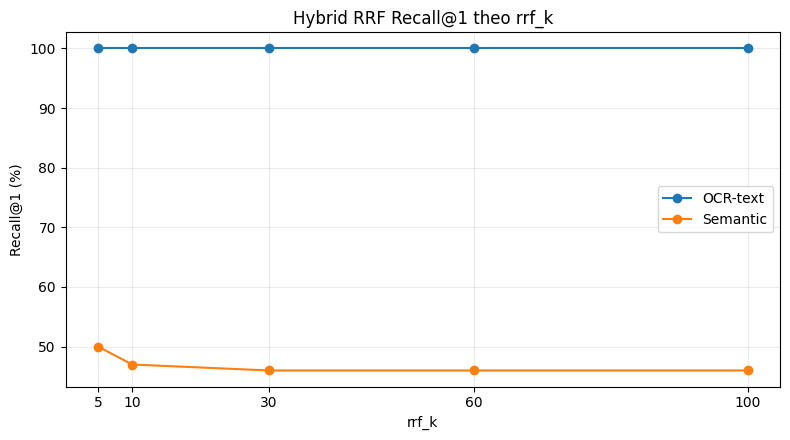

In [15]:
RRF_K_VALUES = [5, 10, 30, 60, 100]
rrf_rows = []
rrf_stats_by_k = {}
for rrf_k in RRF_K_VALUES:
    stats, _ = evaluate(lambda q, k, value=rrf_k: hybrid_ids(q, k, rrf_k=value))
    rrf_stats_by_k[rrf_k] = stats
    rrf_rows.append({
        "rrf_k": rrf_k,
        "OCR-text Recall@1": group_metrics(stats, "OCR-text")["R@1"],
        "Semantic Recall@1": group_metrics(stats, "Semantic")["R@1"],
    })
rrf_df = pd.DataFrame(rrf_rows)
display(rrf_df.round(2))

plt.figure(figsize=(8, 4.5))
plt.plot(rrf_df["rrf_k"], rrf_df["OCR-text Recall@1"], marker="o", label="OCR-text")
plt.plot(rrf_df["rrf_k"], rrf_df["Semantic Recall@1"], marker="o", label="Semantic")
plt.xticks(RRF_K_VALUES)
plt.xlabel("rrf_k")
plt.ylabel("Recall@1 (%)")
plt.title("Hybrid RRF Recall@1 theo rrf_k")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


### Nhận xét đo được — RRF

OCR-text Recall@1 cao nhất tại rrf_k=5 (100.0%), còn Semantic cao nhất tại rrf_k=5 (50.0%). RRF đối xứng giữa BM25 và kNN: rrf_k nhỏ chỉ làm các hạng đầu có ảnh hưởng tương đối mạnh hơn, không mặc nhiên ưu tiên nhánh nào. Khi rrf_k lớn hơn, chênh lệch giữa các hạng liền kề giảm và sự đồng thuận giữa hai danh sách có giá trị tương đối cao hơn.


## Task 4 — Weighted Hybrid

BM25 và kNN lấy cùng độ sâu 30. Điểm của mỗi nhánh được min-max normalize **độc lập theo từng query**; candidate vắng ở một nhánh nhận điểm chuẩn hóa `0` ở nhánh đó.


In [16]:
def min_max_normalize(scores):
    if not scores:
        return {}
    minimum, maximum = min(scores.values()), max(scores.values())
    if maximum == minimum:
        # Mọi candidate nhận cùng bằng chứng tối đa khi nhánh có điểm bằng nhau.
        return {frame_id: 1.0 for frame_id in scores}
    return {
        frame_id: (score - minimum) / (maximum - minimum)
        for frame_id, score in scores.items()
    }

def raw_branch_scores(q):
    bm25, knn = retrieve_branches(q)
    return dict(bm25), dict(knn)

def weighted_ids(q, k=10, alpha=0.5):
    bm25_raw, knn_raw = raw_branch_scores(q)
    bm25_norm = min_max_normalize(bm25_raw)
    knn_norm = min_max_normalize(knn_raw)
    candidates = set(bm25_raw) | set(knn_raw)
    scores = {
        frame_id: alpha * bm25_norm.get(frame_id, 0.0)
        + (1 - alpha) * knn_norm.get(frame_id, 0.0)
        for frame_id in candidates
    }

    def tie_key(frame_id):
        active_present = (
            (alpha > 0 and frame_id in bm25_raw)
            or (alpha < 1 and frame_id in knn_raw)
        )
        active_scores = []
        if alpha > 0:
            active_scores.append(bm25_norm.get(frame_id, 0.0))
        if alpha < 1:
            active_scores.append(knn_norm.get(frame_id, 0.0))
        return (-scores[frame_id], not active_present, -max(active_scores, default=0.0), frame_id)

    return sorted(candidates, key=tie_key)[:k]

ALPHAS = [0, 0.25, 0.5, 0.75, 1]
comparison_rows = []
rrf60_stats = rrf_stats_by_k[60]
rrf_row = {"Method": "RRF k=60"}
for group, prefix in (("OCR-text", "OCR"), ("Semantic", "Semantic")):
    metrics = group_metrics(rrf60_stats, group)
    rrf_row.update({f"{prefix} R@1": metrics["R@1"], f"{prefix} R@5": metrics["R@5"],
                    f"{prefix} MRR": metrics["MRR"]})
comparison_rows.append(rrf_row)

for alpha in ALPHAS:
    stats, _ = evaluate(lambda q, k, value=alpha: weighted_ids(q, k, alpha=value))
    row = {"Method": f"Weighted alpha={alpha:g}"}
    for group, prefix in (("OCR-text", "OCR"), ("Semantic", "Semantic")):
        metrics = group_metrics(stats, group)
        row.update({f"{prefix} R@1": metrics["R@1"], f"{prefix} R@5": metrics["R@5"],
                    f"{prefix} MRR": metrics["MRR"]})
    comparison_rows.append(row)

weighted_comparison_df = pd.DataFrame(comparison_rows)
display(weighted_comparison_df.round(4))

lab6_metrics = {
    "ocr": ocr_comparison_df.to_dict(orient="records"),
    "rrf": rrf_df.to_dict(orient="records"),
    "weighted": weighted_comparison_df.to_dict(orient="records"),
}
with open("lab6_metrics.json", "w", encoding="utf-8") as handle:
    json.dump(lab6_metrics, handle, ensure_ascii=False, indent=2)
print("      => Đã lưu toàn bộ số đo thật vào lab6_metrics.json")


,Method,OCR R@1,OCR R@5,OCR MRR,Semantic R@1,Semantic R@5,Semantic MRR
0,RRF k=60,100.0,100.0,1.000,46.0,89.0,0.6378
1,Weighted alpha=0,80.0,90.0,0.850,75.0,95.0,0.8333
2,Weighted alpha=0.25,90.0,100.0,0.925,74.0,95.0,0.8273
3,Weighted alpha=0.5,100.0,100.0,1.000,58.0,90.0,0.7168
4,Weighted alpha=0.75,100.0,100.0,1.000,4.0,79.0,0.2565
5,Weighted alpha=1,100.0,100.0,1.000,1.0,7.0,0.0638


      => Đã lưu toàn bộ số đo thật vào lab6_metrics.json


### Nhận xét đo được — Weighted Hybrid

Theo trung bình sáu chỉ số đã đo, Weighted alpha=0.25 cho cân bằng tốt nhất trong nhóm Weighted Hybrid. Hai cực trị alpha=0 và alpha=1 lần lượt chỉ giữ đóng góp của CLIP kNN và BM25, nên thể hiện rõ thế mạnh/yếu của từng modality. Kết quả cân bằng Weighted tốt nhất cao hơn RRF k=60 theo cùng cách tổng hợp này; bảng số liệu phía trên vẫn là căn cứ cho từng metric riêng.


---
# Part 3: Online — REST API với FastAPI

## Task 1 — Flexible Object Search API

API giữ `/health`, `/search/text`, `/search/hybrid` và bổ sung `/search/object`. Thư mục `keyframes/` được mount tại `/keyframes`; `top_k` và `rrf_k` có giới hạn, còn malformed `want` trả HTTP 400.


In [17]:
%%writefile app.py
"""Lab 6 — Video Retrieval API (FastAPI + Elasticsearch + CLIP).

Chạy:  uvicorn app:app --host 0.0.0.0 --port 8000
Docs:  http://localhost:8000/docs

Elasticsearch phải chạy ở ``localhost:9200`` và index ``keyframes`` phải
được tạo bởi notebook Lab 6 từ OCR cuối cùng của PaddleOCR.
"""
from collections import Counter
from functools import lru_cache
from pathlib import Path
from typing import Annotated, Iterable, Mapping

import open_clip
import torch
import torch.nn.functional as F
from elasticsearch import Elasticsearch
from fastapi import FastAPI, HTTPException, Query
from fastapi.staticfiles import StaticFiles

ES_URL = "http://localhost:9200"
INDEX = "keyframes"
TOP_N_EACH = 30
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Tên 80 lớp COCO đúng với nhãn của YOLOv8n. Giữ hằng số này nhẹ hơn việc
# nạp thêm một mô hình YOLO chỉ để kiểm tra tham số HTTP.
COCO_CLASSES = frozenset(
    (
        "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck",
        "boat", "traffic light", "fire hydrant", "stop sign", "parking meter", "bench",
        "bird", "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra",
        "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
        "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove",
        "skateboard", "surfboard", "tennis racket", "bottle", "wine glass", "cup", "fork",
        "knife", "spoon", "bowl", "banana", "apple", "sandwich", "orange", "broccoli",
        "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch", "potted plant",
        "bed", "dining table", "toilet", "tv", "laptop", "mouse", "remote", "keyboard",
        "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "book",
        "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush",
    )
)

BASE_DIR = Path(__file__).resolve().parent
KEYFRAME_DIR = BASE_DIR / "keyframes"
KEYFRAME_DIR.mkdir(parents=True, exist_ok=True)

app = FastAPI(title="Lab 6 — Video Retrieval API")
app.mount("/keyframes", StaticFiles(directory=KEYFRAME_DIR), name="keyframes")
es = Elasticsearch(ES_URL)


@lru_cache(maxsize=1)
def clip_components():
    """Nạp CLIP một lần, khi truy vấn hybrid đầu tiên thực sự cần đến nó."""
    model, _, _ = open_clip.create_model_and_transforms(
        "RN50", pretrained="openai", device=DEVICE
    )
    model.eval()
    return model, open_clip.get_tokenizer("RN50")


def text_vector(q: str) -> list:
    """Mã hóa truy vấn thành vector CLIP RN50 1024 chiều đã chuẩn hóa L2."""
    model, tokenizer = clip_components()
    with torch.no_grad():
        vector = F.normalize(model.encode_text(tokenizer([q]).to(DEVICE)), dim=-1)
    return vector.cpu().numpy()[0].tolist()


def parse_object_want(want: str) -> list[tuple[str, int]]:
    """Parse ``class:minimum`` conditions and reject malformed input as HTTP 400."""
    if not want or not want.strip():
        raise HTTPException(status_code=400, detail="want must contain at least one class:count condition")

    conditions: list[tuple[str, int]] = []
    seen: set[str] = set()
    for raw_condition in want.split(","):
        condition = raw_condition.strip()
        if ":" not in condition:
            raise HTTPException(
                status_code=400,
                detail=f"Invalid condition '{condition}': expected COCO-class:non-negative-count",
            )
        class_name, count_text = (part.strip() for part in condition.rsplit(":", 1))
        if not class_name:
            raise HTTPException(status_code=400, detail="Object class name cannot be empty")
        if class_name not in COCO_CLASSES:
            raise HTTPException(status_code=400, detail=f"Unknown COCO class '{class_name}'")
        if not count_text.isdigit():
            raise HTTPException(
                status_code=400,
                detail=f"Count for '{class_name}' must be a non-negative integer",
            )
        if class_name in seen:
            raise HTTPException(status_code=400, detail=f"Duplicate COCO class '{class_name}'")
        seen.add(class_name)
        conditions.append((class_name, int(count_text)))
    return conditions


def build_object_filters(conditions: Iterable[tuple[str, int]]) -> list[dict]:
    """Translate parsed conditions into Elasticsearch dynamic range filters."""
    return [
        {"range": {f"objects.{class_name}": {"gte": minimum}}}
        for class_name, minimum in conditions
    ]


def hit_payload(hit: Mapping) -> dict:
    """Return the stable public fields shared by all search endpoints."""
    source = hit["_source"]
    frame_id = source["frame_id"]
    return {
        "frame_id": frame_id,
        "video_id": source["video_id"],
        "ts": source["ts"],
        "score": float(hit.get("_score") or 0.0),
        "ocr_text": source.get("ocr_text", ""),
        "caption": source.get("caption", ""),
        "objects": source.get("objects", {}),
        "image_path": f"/keyframes/{frame_id}.jpg",
        "highlight": hit.get("highlight", {}),
    }


def rrf_fuse(lists: Iterable[Iterable[str]], rrf_k: int = 60, top: int = 10) -> list[str]:
    """Fuse ranked ID lists symmetrically with Reciprocal Rank Fusion."""
    if rrf_k <= 0:
        raise ValueError("rrf_k must be positive")
    scores: Counter = Counter()
    for ranked_ids in lists:
        for rank, frame_id in enumerate(ranked_ids, start=1):
            scores[frame_id] += 1.0 / (rrf_k + rank)
    return [
        frame_id
        for frame_id, _ in sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:top]
    ]


def min_max_normalize(scores: Mapping[str, float]) -> dict[str, float]:
    """Normalize one query branch; equal non-empty scores all become 1.0."""
    if not scores:
        return {}
    minimum = min(scores.values())
    maximum = max(scores.values())
    if maximum == minimum:
        # Equal candidates retain equal maximal evidence instead of losing the branch.
        return {frame_id: 1.0 for frame_id in scores}
    scale = maximum - minimum
    return {frame_id: (score - minimum) / scale for frame_id, score in scores.items()}


def weighted_fuse(
    bm25_scores: Mapping[str, float],
    knn_scores: Mapping[str, float],
    alpha: float,
    top: int = 10,
) -> list[tuple[str, float]]:
    """Fuse independently normalized BM25/kNN scores for one query."""
    if not 0.0 <= alpha <= 1.0:
        raise ValueError("alpha must be between 0 and 1")
    bm25_normalized = min_max_normalize(bm25_scores)
    knn_normalized = min_max_normalize(knn_scores)
    candidates = set(bm25_scores) | set(knn_scores)
    combined = {
        frame_id: alpha * bm25_normalized.get(frame_id, 0.0)
        + (1.0 - alpha) * knn_normalized.get(frame_id, 0.0)
        for frame_id in candidates
    }

    def tie_key(frame_id: str):
        active_present = (
            (alpha > 0.0 and frame_id in bm25_scores)
            or (alpha < 1.0 and frame_id in knn_scores)
        )
        active_scores = []
        if alpha > 0.0:
            active_scores.append(bm25_normalized.get(frame_id, 0.0))
        if alpha < 1.0:
            active_scores.append(knn_normalized.get(frame_id, 0.0))
        corresponding_score = max(active_scores, default=0.0)
        return (-combined[frame_id], not active_present, -corresponding_score, frame_id)

    ordered = sorted(candidates, key=tie_key)[:top]
    return [(frame_id, combined[frame_id]) for frame_id in ordered]


@app.get("/health")
def health():
    return {"status": "ok", "docs": es.count(index=INDEX)["count"]}


@app.get("/search/text")
def search_text(
    q: str = "",
    person_min: Annotated[int, Query(ge=0)] = 0,
    car_min: Annotated[int, Query(ge=0)] = 0,
    top_k: Annotated[int, Query(ge=1, le=100)] = 5,
):
    """BM25 trên OCR/caption, giữ tương thích filter person/car của Lab 5."""
    bool_query = {
        "must": (
            [{"multi_match": {"query": q, "fields": ["ocr_text^2", "caption"]}}]
            if q
            else [{"match_all": {}}]
        ),
        "filter": [],
    }
    if person_min:
        bool_query["filter"].append({"range": {"objects.person": {"gte": person_min}}})
    if car_min:
        bool_query["filter"].append({"range": {"objects.car": {"gte": car_min}}})
    response = es.search(
        index=INDEX,
        size=top_k,
        query={"bool": bool_query},
        highlight={"fields": {"ocr_text": {}}},
    )
    return {
        "query": q,
        "total": response["hits"]["total"]["value"],
        "hits": [hit_payload(hit) for hit in response["hits"]["hits"]],
    }


@app.get("/search/object")
def search_object(
    want: str,
    top_k: Annotated[int, Query(ge=1, le=100)] = 5,
):
    """Filter arbitrary valid COCO classes expressed as ``class:min`` pairs."""
    conditions = parse_object_want(want)
    filters = build_object_filters(conditions)
    response = es.search(index=INDEX, size=top_k, query={"bool": {"filter": filters}})
    return {
        "want": want,
        "conditions": dict(conditions),
        "total": response["hits"]["total"]["value"],
        "hits": [hit_payload(hit) for hit in response["hits"]["hits"]],
    }


@app.get("/search/hybrid")
def search_hybrid(
    q: str,
    top_k: Annotated[int, Query(ge=1, le=100)] = 5,
    rrf_k: Annotated[int, Query(ge=1, le=1000)] = 60,
):
    """BM25 + CLIP kNN fused symmetrically with explicit ``rrf_k``."""
    bm25 = es.search(
        index=INDEX,
        size=TOP_N_EACH,
        query={"multi_match": {"query": q, "fields": ["ocr_text^2", "caption"]}},
    )
    knn = es.search(
        index=INDEX,
        size=TOP_N_EACH,
        knn={
            "field": "clip_vector",
            "query_vector": text_vector(q),
            "k": TOP_N_EACH,
            "num_candidates": 200,
        },
    )

    ranked_lists = []
    payloads: dict[str, dict] = {}
    for response, tag in ((bm25, "bm25"), (knn, "knn")):
        ranked = []
        for rank, hit in enumerate(response["hits"]["hits"], start=1):
            frame_id = hit["_source"]["frame_id"]
            ranked.append(frame_id)
            payloads.setdefault(frame_id, hit_payload(hit))[f"rank_{tag}"] = rank
        ranked_lists.append(ranked)

    fused_ids = rrf_fuse(ranked_lists, rrf_k=rrf_k, top=top_k)
    rrf_scores: Counter = Counter()
    for ranked in ranked_lists:
        for rank, frame_id in enumerate(ranked, start=1):
            rrf_scores[frame_id] += 1.0 / (rrf_k + rank)

    hits = []
    for frame_id in fused_ids:
        payload = payloads[frame_id]
        payload["score"] = round(rrf_scores[frame_id], 8)
        hits.append(payload)
    return {"query": q, "rrf_k": rrf_k, "hits": hits}


Overwriting app.py


In [18]:
print("Khởi động API server và chạy smoke tests...")
API_URL = "http://127.0.0.1:8000"
api_server = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"],
    stdout=open("uvicorn.log", "w", encoding="utf-8"),
    stderr=subprocess.STDOUT,
    creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0),
)
for _ in range(90):
    try:
        if requests.get(f"{API_URL}/health", timeout=3).ok:
            break
    except requests.exceptions.RequestException:
        pass
    time.sleep(2)

health_response = requests.get(f"{API_URL}/health", timeout=10)
health_response.raise_for_status()
print("GET /health ->", health_response.status_code, health_response.json())

smoke_cases = [
    ("/search/text", {"q": "giá vàng tăng", "top_k": 3}),
    ("/search/object", {"want": "person:2,car:1", "top_k": 3}),
    ("/search/object", {"want": "person:2,car:1,dog:1", "top_k": 3}),
    ("/search/hybrid", {"q": "đàm phán Mỹ Iran", "top_k": 3, "rrf_k": 60}),
]
smoke_payloads = []
for path, params in smoke_cases:
    response = requests.get(f"{API_URL}{path}", params=params, timeout=120)
    response.raise_for_status()
    payload = response.json()
    smoke_payloads.append(payload)
    print("GET", response.url, "->", response.status_code, "hits=", len(payload.get("hits", [])))

bad_response = requests.get(
    f"{API_URL}/search/object", params={"want": "person:abc"}, timeout=10
)
assert bad_response.status_code == 400, bad_response.text
print('GET /search/object?want="person:abc" ->', bad_response.status_code, bad_response.json())

image_hit = next(
    hit for payload in smoke_payloads for hit in payload.get("hits", []) if hit.get("image_path")
)
image_response = requests.get(f"{API_URL}{image_hit['image_path']}", timeout=10)
assert image_response.status_code == 200 and image_response.headers["content-type"].startswith("image/")
print("GET", image_hit["image_path"], "->", image_response.status_code,
      image_response.headers["content-type"], len(image_response.content), "bytes")

openapi_response = requests.get(f"{API_URL}/openapi.json", timeout=10)
openapi_response.raise_for_status()
assert "/search/object" in openapi_response.json()["paths"]
print("OpenAPI chứa /search/object: True")


Khởi động API server và chạy smoke tests...
GET /health -> 200 {'status': 'ok', 'docs': 300}
GET http://127.0.0.1:8000/search/text?q=gi%C3%A1+v%C3%A0ng+t%C4%83ng&top_k=3 -> 200 hits= 3
GET http://127.0.0.1:8000/search/object?want=person%3A2%2Ccar%3A1&top_k=3 -> 200 hits= 3
GET http://127.0.0.1:8000/search/object?want=person%3A2%2Ccar%3A1%2Cdog%3A1&top_k=3 -> 200 hits= 0
GET http://127.0.0.1:8000/search/hybrid?q=%C4%91%C3%A0m+ph%C3%A1n+M%E1%BB%B9+Iran&top_k=3&rrf_k=60 -> 200 hits= 3
GET /search/object?want="person:abc" -> 400 {'detail': "Count for 'person' must be a non-negative integer"}
GET /keyframes/V00_F008.jpg -> 200 image/jpeg 51940 bytes
OpenAPI chứa /search/object: True
